# fleetsim v0.1 — fleet analytics in SQL

Every simulation tick is logged to SQLite (`results/fleetsim.db`, also Parquet under `results/parquet/`).
Regenerate with `fleetsim bench --out results` (about 2 minutes), then re-run this notebook.

Tables

| table | grain | key columns |
|---|---|---|
| `runs` | one row per simulation | `run_id`, `n_robots`, `allocator`, `load`, `rate_per_tick` |
| `ticks` | robot x tick | `tick`, `robot`, `row`, `col`, `state`, `moved`, `waiting`, `order_id` |
| `orders` | order | `created`, `assigned`, `picked`, `at_station`, `serviced`, `completed`, `free_flow` (`-1` = not yet) |
| `plans` | planner call | `tick`, `robot`, `ms`, `ok`, `expansions`, `n_pending` |

1 tick = 1 s. The first `warmup` ticks of each run (600) are excluded from KPIs.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DB = Path("../results/fleetsim.db")
con = sqlite3.connect(DB)
q = lambda sql: pd.read_sql_query(sql, con)
q("SELECT run_id, n_robots, allocator, load, ROUND(rate_per_tick*3600) AS orders_per_h, ROUND(wall_s,1) AS wall_s FROM runs")

,run_id,n_robots,allocator,load,orders_per_h,wall_s
0,n10_greedy_load0.85_s0,10,greedy,0.85,131.0,1.2
1,n10_hungarian_load0.85_s0,10,hungarian,0.85,131.0,1.2
2,n50_greedy_load0.85_s0,50,greedy,0.85,655.0,3.9
3,n50_hungarian_load0.85_s0,50,hungarian,0.85,655.0,4.2
4,n100_greedy_load0.85_s0,100,greedy,0.85,1322.0,9.1
5,n100_hungarian_load0.85_s0,100,hungarian,0.85,1322.0,9.1
6,n10_greedy_load1.3_s0,10,greedy,1.30,200.0,1.5
7,n10_hungarian_load1.3_s0,10,hungarian,1.30,200.0,1.5
8,n50_greedy_load1.3_s0,50,greedy,1.30,1002.0,5.3
9,n50_hungarian_load1.3_s0,50,hungarian,1.30,1002.0,5.2


## 1. Fleet KPIs per run
Throughput counts pods returned to storage inside the measured hour. Utilization = share of robot-ticks spent on an order (to_pod … drop). Travel-wait = share of travelling robot-ticks (`to_pod`, `to_station`, `return`) after which the robot stays put (`waiting = 1`), i.e. it yields to another robot or waits for a busy station.

In [2]:
kpi = q('''
WITH w AS (SELECT run_id, warmup, warmup + ticks AS t_end, n_robots, allocator, load FROM runs),
done AS (
  SELECT o.run_id, COUNT(*) AS completed,
         AVG(o.completed - o.assigned - o.free_flow) AS congestion_delay_s,
         AVG(o.completed - o.created) AS lead_time_s
  FROM orders o JOIN w USING (run_id)
  WHERE o.completed >= w.warmup AND o.completed >= 0
  GROUP BY o.run_id),
tk AS (
  SELECT t.run_id,
         AVG(t.state IN ('to_pod','lift','to_station','service','return','drop')) AS utilization,
         1.0 * SUM(t.waiting) / SUM(t.state IN ('to_pod','to_station','return')) AS travel_wait_share
  FROM ticks t JOIN w USING (run_id)
  WHERE t.tick >= w.warmup AND t.tick < w.t_end - 1
  GROUP BY t.run_id)
SELECT w.n_robots, w.allocator, w.load,
       ROUND(done.completed * 3600.0 / (w.t_end - w.warmup)) AS tasks_per_h,
       ROUND(tk.utilization, 3) AS utilization,
       ROUND(tk.travel_wait_share, 3) AS travel_wait_share,
       ROUND(done.congestion_delay_s, 1) AS congestion_delay_s,
       ROUND(done.lead_time_s, 1) AS lead_time_s
FROM w JOIN done USING (run_id) JOIN tk USING (run_id)
ORDER BY w.load, w.n_robots, w.allocator
''')
kpi

,n_robots,allocator,load,tasks_per_h,utilization,travel_wait_share,congestion_delay_s,lead_time_s
0,10,greedy,0.85,122.0,0.727,0.001,0.7,209.1
1,10,hungarian,0.85,122.0,0.712,0.001,0.4,206.2
2,50,greedy,0.85,658.0,0.723,0.008,3.0,198.5
3,50,hungarian,0.85,651.0,0.723,0.009,3.3,200.1
4,100,greedy,0.85,1335.0,0.707,0.021,7.3,193.2
5,100,hungarian,0.85,1340.0,0.704,0.020,7.0,194.5
6,10,greedy,1.30,171.0,1.000,0.001,0.7,642.4
7,10,hungarian,1.30,198.0,0.989,0.002,0.7,367.6
8,50,greedy,1.30,819.0,1.000,0.009,4.1,556.8
9,50,hungarian,1.30,982.0,0.989,0.013,3.8,265.2


## 2. Order waiting time (censored)
Orders still unassigned at the end of the run count with the wait accrued so far, so an allocator cannot look good by never serving its hardest orders.

In [3]:
wait = q('''
WITH w AS (SELECT run_id, warmup, warmup + ticks AS t_end, n_robots, allocator, load FROM runs)
SELECT w.n_robots, w.allocator, w.load,
       COUNT(*) AS orders,
       SUM(o.assigned < 0) AS backlog_end,
       ROUND(AVG(CASE WHEN o.assigned >= 0 THEN o.assigned ELSE w.t_end END - o.created), 1) AS mean_wait_s,
       MAX(CASE WHEN o.assigned >= 0 THEN o.assigned ELSE w.t_end END - o.created) AS max_wait_s
FROM orders o JOIN w USING (run_id)
WHERE o.created >= w.warmup
GROUP BY o.run_id ORDER BY w.load, w.n_robots, w.allocator
''')
wait

,n_robots,allocator,load,orders,backlog_end,mean_wait_s,max_wait_s
0,10,greedy,0.85,130,2,3.3,55
1,10,hungarian,0.85,130,2,4.4,61
2,50,greedy,0.85,655,0,0.0,1
3,50,hungarian,0.85,655,0,2.0,4
4,100,greedy,0.85,1310,0,0.0,2
5,100,hungarian,0.85,1310,2,2.0,19
6,10,greedy,1.30,215,46,461.4,877
7,10,hungarian,1.30,215,17,211.9,1202
8,50,greedy,1.30,1019,219,376.2,699
9,50,hungarian,1.30,1019,55,90.8,599


## 3. Where does congestion happen?
Robot-ticks spent waiting while travelling, by grid cell, for the largest overloaded fleet.

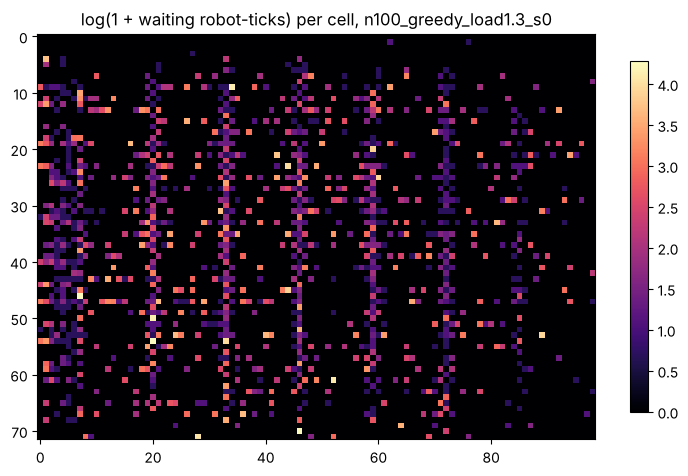

,row,col,waits
959,54,20,71
792,46,7,71
1168,70,46,69
879,50,20,62
53,9,34,60
1071,61,52,59
1172,71,28,56
309,23,44,53
960,54,33,52
951,53,89,49


In [4]:
big = q("SELECT run_id FROM runs ORDER BY load DESC, n_robots DESC, allocator LIMIT 1").run_id[0]
hot = q(f'''
SELECT row, col, COUNT(*) AS waits
FROM ticks
WHERE run_id = '{big}' AND waiting = 1
GROUP BY row, col
''')
H = q(f"SELECT MAX(row)+1 AS h, MAX(col)+1 AS w FROM ticks WHERE run_id = '{big}'").iloc[0]
grid = np.zeros((int(H.h), int(H.w)))
grid[hot.row, hot.col] = hot.waits
fig, ax = plt.subplots(figsize=(9, 6.5))
im = ax.imshow(np.log1p(grid), cmap="magma")
ax.set_title(f"log(1 + waiting robot-ticks) per cell, {big}")
fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()
hot.sort_values("waits", ascending=False).head(10)

## 4. Planner runtime
One planner call = a full errand (robot→pod→station→pod→home) planned with space-time A* against all existing reservations.

In [5]:
q('''
SELECT r.n_robots, r.allocator, r.load,
       COUNT(*) AS calls,
       ROUND(AVG(p.ms), 2) AS mean_ms,
       ROUND(MAX(p.ms), 1) AS max_ms,
       ROUND(AVG(p.expansions)) AS mean_expansions,
       ROUND(1.0 - AVG(p.ok), 4) AS fail_rate
FROM plans p JOIN runs r USING (run_id)
WHERE p.tick >= r.warmup
GROUP BY p.run_id ORDER BY r.load, r.n_robots, r.allocator
''')

,n_robots,allocator,load,calls,mean_ms,max_ms,mean_expansions,fail_rate
0,10,greedy,0.85,128,0.96,9.9,342.0,0.0000
1,10,hungarian,0.85,128,0.91,7.0,284.0,0.0000
2,50,greedy,0.85,656,1.65,24.4,506.0,0.0015
3,50,hungarian,0.85,656,1.79,104.0,533.0,0.0000
4,100,greedy,0.85,1313,2.66,76.7,895.0,0.0023
5,100,hungarian,0.85,1313,2.66,145.7,873.0,0.0038
6,10,greedy,1.30,171,1.10,6.3,296.0,0.0000
7,10,hungarian,1.30,198,1.02,6.7,270.0,0.0000
8,50,greedy,1.30,835,2.13,67.4,676.0,0.0192
9,50,hungarian,1.30,981,1.52,14.2,420.0,0.0000


## 5. Hourly station load
Picks per station in the measured hour — are stations a bottleneck?

In [6]:
q('''
SELECT r.n_robots, r.allocator, r.load,
       COUNT(DISTINCT o.station) AS stations_used,
       ROUND(1.0 * COUNT(*) / COUNT(DISTINCT o.station), 1) AS picks_per_station,
       ROUND(100.0 * COUNT(*) * r.service / (COUNT(DISTINCT o.station) * r.ticks), 1) AS station_busy_pct
FROM orders o JOIN runs r USING (run_id)
WHERE o.serviced >= r.warmup
GROUP BY o.run_id ORDER BY r.load, r.n_robots, r.allocator
''')

,n_robots,allocator,load,stations_used,picks_per_station,station_busy_pct
0,10,greedy,0.85,19,6.6,1.8
1,10,hungarian,0.85,19,6.6,1.8
2,50,greedy,0.85,19,34.5,9.6
3,50,hungarian,0.85,19,34.4,9.6
4,100,greedy,0.85,19,69.6,19.3
5,100,hungarian,0.85,19,69.6,19.3
6,10,greedy,1.30,19,9.1,2.5
7,10,hungarian,1.30,19,10.5,2.9
8,50,greedy,1.30,19,43.2,12.0
9,50,hungarian,1.30,19,51.7,14.4
